# CSET312 AI-ML Lab, Week 11: Sentiment Analysis with RNN (vs ANN, bonus LSTM)

**Name:** Harshit Poonia &nbsp;|&nbsp; **Enrollment:** S24CSEU2835 &nbsp;|&nbsp; **Batch:** B93

**Objective.** Classify Amazon product reviews as positive or negative with a Recurrent Neural Network, study how the
hyperparameters change accuracy and loss, compare against a baseline ANN, and (bonus) against an LSTM.

**Dataset.** Kaggle `yasserh/amazon-product-reviews-dataset` (file `7817_1.csv`). Only `reviews.text` and `reviews.rating` are used.

**Labelling rule.** rating 4 or 5 → positive (1), rating 1, 2 or 3 → negative (0). Rows without a rating are dropped.
3-star reviews mostly complain about something, so I count them as "not positive". Without them there would be only 76 negative reviews.

In [1]:
import os, re, time, random, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, confusion_matrix,
                             classification_report, ConfusionMatrixDisplay)
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); tf.random.set_seed(s)
tf.get_logger().setLevel("ERROR")   # hides the retracing warnings from the sweep loop
set_seed()
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 1. Load the data

In [2]:
DATA_PATH = "7817_1.csv"   # put the Kaggle CSV next to this notebook
raw = pd.read_csv(DATA_PATH, low_memory=False)
print("Full dataset shape:", raw.shape)

df = raw[["reviews.text", "reviews.rating"]].dropna().copy()
df.columns = ["text", "rating"]
df["label"] = (df["rating"] >= 4).astype(int)
print("After dropping missing ratings:", df.shape)
print(df["rating"].value_counts().sort_index())
print("\nLabel counts (1 = positive):")
print(df["label"].value_counts())
df.head()

Full dataset shape: (1597, 27)
After dropping missing ratings: (1177, 3)
rating
1.0     42
2.0     34
3.0    124
4.0    236
5.0    741
Name: count, dtype: int64

Label counts (1 = positive):
label
1    977
0    200
Name: count, dtype: int64


,text,rating,label
0,I initially had trouble deciding between the p...,5.0,1
1,Allow me to preface this with a little history...,5.0,1
2,I am enjoying it so far. Great for reading. Ha...,4.0,1
3,I bought one of the first Paperwhites and have...,5.0,1
4,I have to say upfront - I don't like coroporat...,5.0,1


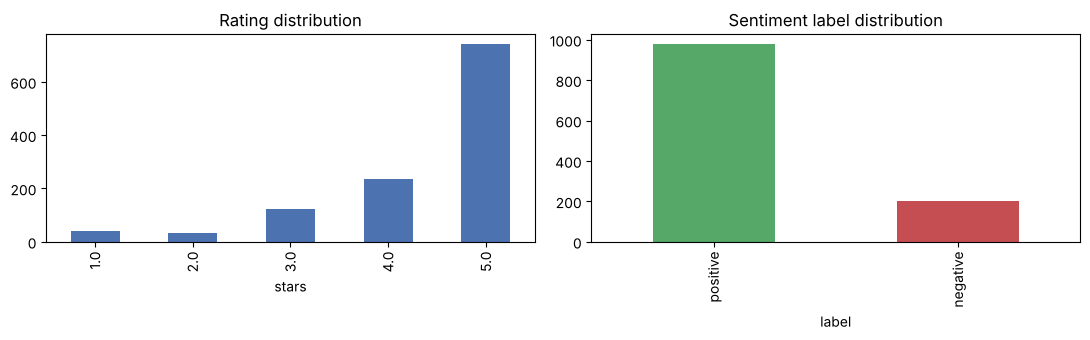

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
df["rating"].value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Rating distribution"); ax[0].set_xlabel("stars")
df["label"].map({1: "positive", 0: "negative"}).value_counts().plot.bar(ax=ax[1], color=["#55A868", "#C44E52"])
ax[1].set_title("Sentiment label distribution")
plt.tight_layout(); plt.show()

The classes are imbalanced (about 83% positive). A model that always says "positive" already gets ~83% accuracy,
so I also report **macro F1**, and I train with **class weights** so the minority class (negative) is not ignored.

## 2. Preprocessing: cleaning and tokenizing

In [4]:
# small stopword list; negation words like "not", "no", "never" are kept on purpose
STOP = set("""a an the and or but if of at by for with about to from in on is are was were be been being
this that these those it its i me my we our you your he she they them their am do does did have has had
so than too very s t can will just should now as into up down out over again then there here when where
which who whom what all any both each few more most other some such own same""".split())

def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"<.*?>", " ", t)              # html tags
    t = re.sub(r"http\S+|www\.\S+", " ", t)  # urls
    t = re.sub(r"n't", " not", t)             # don't -> do not
    t = re.sub(r"[^a-z\s]", " ", t)           # keep letters only
    tokens = [w for w in t.split() if w not in STOP and len(w) > 1]
    return " ".join(tokens)

df["clean"] = df["text"].apply(clean_text)
for i in range(3):
    print("RAW  :", df["text"].iloc[i][:150])
    print("CLEAN:", df["clean"].iloc[i][:150], "\n")

lens = df["clean"].str.split().str.len()
print(lens.describe())

RAW  : I initially had trouble deciding between the paperwhite and the voyage because reviews more or less said the same thing: the paperwhite is great, but 
CLEAN: initially trouble deciding between paperwhite voyage because reviews less said thing paperwhite great spending money go voyage fortunately friends own 

RAW  : Allow me to preface this with a little history. I am (was) a casual reader who owned a Nook Simple Touch from 2011. I've read the Harry Potter series,
CLEAN: allow preface little history casual reader owned nook simple touch ve read harry potter series girl dragon tattoo series brave new world key titles fa 

RAW  : I am enjoying it so far. Great for reading. Had the original Fire since 2012. The Fire used to make my eyes hurt if I read too long. Haven't experienc
CLEAN: enjoying far great reading original fire since fire used make eyes hurt read long not experienced paperwhite yet 

count    1177.000000
mean       72.041631
std       125.454537
min         0.000000


In [5]:
X_train, X_tmp, y_train, y_tmp = train_test_split(df["clean"].values, df["label"].values,
                                                  test_size=0.30, stratify=df["label"], random_state=SEED)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.50,
                                                stratify=y_tmp, random_state=SEED)
print("train", len(X_train), "| val", len(X_val), "| test", len(X_test))

VOCAB_SIZE = 5000
MAX_LEN = 150     # covers ~75% of reviews fully, longer ones are truncated
vectorizer = layers.TextVectorization(max_tokens=VOCAB_SIZE, output_sequence_length=MAX_LEN,
                                      standardize=None)   # already cleaned above
vectorizer.adapt(X_train)    # vocabulary built only from training data (no leakage)

Xtr = vectorizer(X_train).numpy(); Xva = vectorizer(X_val).numpy(); Xte = vectorizer(X_test).numpy()
print("Tokenised + padded shape:", Xtr.shape)
print("First 10 vocabulary words:", vectorizer.get_vocabulary()[:12])
print("Example sequence:", Xtr[0][:20])

cw = compute_class_weight("balanced", classes=np.array([0, 1]), y=y_train)
CLASS_WEIGHT = {0: cw[0], 1: cw[1]}
print("Class weights:", CLASS_WEIGHT)

train 823 | val 177 | test 177


Tokenised + padded shape: (823, 150)
First 10 vocabulary words: ['', '[UNK]', np.str_('not'), np.str_('amazon'), np.str_('fire'), np.str_('like'), np.str_('kindle'), np.str_('great'), np.str_('sound'), np.str_('one'), np.str_('use'), np.str_('would')]
Example sequence: [ 646    6   99  100   25    9  837    6 1634  187   27   76 4147 1021
  890 2550  732 3061   25   39]
Class weights: {0: np.float64(2.9392857142857145), 1: np.float64(0.6024890190336749)}


**Word embeddings.** Every token id goes into a trainable `Embedding` layer that maps it to a dense vector
(size 16 or 32). Words used in similar contexts end up with similar vectors, so the model works with meaning
instead of sparse one-hot ids. `mask_zero=True` tells the recurrent layers to skip the padding.

## 3. Model builders and training helper

In [6]:
def get_opt(name):
    return keras.optimizers.Adam(1e-3) if name == "adam" else keras.optimizers.RMSprop(1e-3)

def build_ann(embedding_size=32, hidden_size=128, dropout=0.3, optimizer="adam"):
    # baseline: averages the word vectors, so word ORDER is lost
    m = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, embedding_size),
        layers.GlobalAveragePooling1D(),
        layers.Dense(hidden_size, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=get_opt(optimizer), loss="binary_crossentropy", metrics=["accuracy"])
    return m

def build_rnn(embedding_size=32, hidden_size=128, dropout=0.3, optimizer="adam", cell="rnn"):
    rec = layers.SimpleRNN if cell == "rnn" else layers.LSTM
    m = keras.Sequential([
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, embedding_size, mask_zero=True),
        rec(hidden_size),                 # reads the sequence word by word, keeps a hidden state
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid")])
    m.compile(optimizer=get_opt(optimizer), loss="binary_crossentropy", metrics=["accuracy"])
    return m

def run(kind="rnn", embedding_size=32, hidden_size=128, dropout=0.3, batch_size=64,
        num_epochs=15, optimizer="adam", verbose=0):
    set_seed()
    if kind == "ann":
        model = build_ann(embedding_size, hidden_size, dropout, optimizer)
    else:
        model = build_rnn(embedding_size, hidden_size, dropout, optimizer, cell=kind)
    t0 = time.time()
    hist = model.fit(Xtr, y_train, validation_data=(Xva, y_val), epochs=num_epochs,
                     batch_size=batch_size, class_weight=CLASS_WEIGHT, verbose=verbose)
    t = time.time() - t0
    prob = model.predict(Xte, verbose=0).ravel()
    pred = (prob >= 0.5).astype(int)
    loss = model.evaluate(Xte, y_test, verbose=0)[0]
    res = dict(model=kind.upper(), embedding_size=embedding_size, hidden_size=hidden_size, dropout=dropout,
               batch_size=batch_size, num_epochs=num_epochs, optimizer=optimizer,
               train_acc=hist.history["accuracy"][-1], val_acc=hist.history["val_accuracy"][-1],
               test_acc=accuracy_score(y_test, pred), test_loss=loss,
               macro_f1=f1_score(y_test, pred, average="macro"), train_time_s=t)
    return res, hist, model, pred

def plot_history(hist, title):
    h = hist.history
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
    ax[0].plot(h["accuracy"], label="train"); ax[0].plot(h["val_accuracy"], label="validation")
    ax[0].set_title(f"{title}: accuracy"); ax[0].set_xlabel("epoch"); ax[0].legend()
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="validation")
    ax[1].set_title(f"{title}: loss"); ax[1].set_xlabel("epoch"); ax[1].legend()
    plt.tight_layout(); plt.show()

## 4. RNN hyperparameter experiments

The full grid in the brief is 2 × 3 × 3 × 4 × 4 × 2 = 576 runs, which is too many for a lab. So I use a
**one-factor-at-a-time** sweep: start from a base config
(embedding 32, hidden 128, dropout 0.3, batch 64, epochs 15, adam), change one hyperparameter over all
the values given in the brief, and keep the rest fixed. That covers every listed value in 13 unique runs.

In [7]:
BASE = dict(embedding_size=32, hidden_size=128, dropout=0.3, batch_size=64, num_epochs=15, optimizer="adam")
GRID = {"embedding_size": [16, 32], "hidden_size": [64, 128, 256], "dropout": [0, 0.3, 0.5],
        "batch_size": [32, 64, 128, 256], "num_epochs": [10, 15, 20, 25], "optimizer": ["adam", "rmsprop"]}

rows, seen = [], {}
for param, values in GRID.items():
    for v in values:
        cfg = {**BASE, param: v}
        key = tuple(cfg.values())
        if key not in seen:
            seen[key], _, _, _ = run("rnn", **cfg)
        r = dict(seen[key]); r["varied"] = param
        rows.append(r)
        print(f"{param:>14} = {str(v):<7} test_acc={r['test_acc']:.3f}  macro_f1={r['macro_f1']:.3f}  loss={r['test_loss']:.3f}")

sweep = pd.DataFrame(rows)
cols = ["varied", "embedding_size", "hidden_size", "dropout", "batch_size", "num_epochs", "optimizer",
        "train_acc", "val_acc", "test_acc", "test_loss", "macro_f1", "train_time_s"]
sweep[cols].round(3)

embedding_size = 16      test_acc=0.836  macro_f1=0.733  loss=0.413


embedding_size = 32      test_acc=0.836  macro_f1=0.688  loss=0.430


   hidden_size = 64      test_acc=0.853  macro_f1=0.746  loss=0.394
   hidden_size = 128     test_acc=0.836  macro_f1=0.688  loss=0.430


   hidden_size = 256     test_acc=0.559  macro_f1=0.491  loss=0.667


       dropout = 0       test_acc=0.842  macro_f1=0.719  loss=0.371
       dropout = 0.3     test_acc=0.836  macro_f1=0.688  loss=0.430


       dropout = 0.5     test_acc=0.836  macro_f1=0.713  loss=0.422


... (4 outputs left out)

    num_epochs = 20      test_acc=0.836  macro_f1=0.678  loss=0.511


    num_epochs = 25      test_acc=0.831  macro_f1=0.682  loss=0.525
     optimizer = adam    test_acc=0.836  macro_f1=0.688  loss=0.430


     optimizer = rmsprop test_acc=0.825  macro_f1=0.676  loss=0.361


,varied,embedding_size,hidden_size,dropout,batch_size,num_epochs,optimizer,train_acc,val_acc,test_acc,test_loss,macro_f1,train_time_s
0,embedding_size,16,128,0.3,64,15,adam,0.944,0.825,0.836,0.413,0.733,19.435
1,embedding_size,32,128,0.3,64,15,adam,0.994,0.842,0.836,0.430,0.688,19.198
2,hidden_size,32,64,0.3,64,15,adam,0.999,0.859,0.853,0.394,0.746,17.232
3,hidden_size,32,128,0.3,64,15,adam,0.994,0.842,0.836,0.430,0.688,19.198
4,hidden_size,32,256,0.3,64,15,adam,0.625,0.525,0.559,0.667,0.491,30.676
5,dropout,32,128,0.0,64,15,adam,0.999,0.825,0.842,0.371,0.719,18.224
6,dropout,32,128,0.3,64,15,adam,0.994,0.842,0.836,0.430,0.688,19.198
7,dropout,32,128,0.5,64,15,adam,0.919,0.808,0.836,0.422,0.713,18.310
8,batch_size,32,128,0.3,32,15,adam,0.999,0.808,0.768,0.646,0.646,31.698
9,batch_size,32,128,0.3,64,15,adam,0.994,0.842,0.836,0.430,0.688,19.198


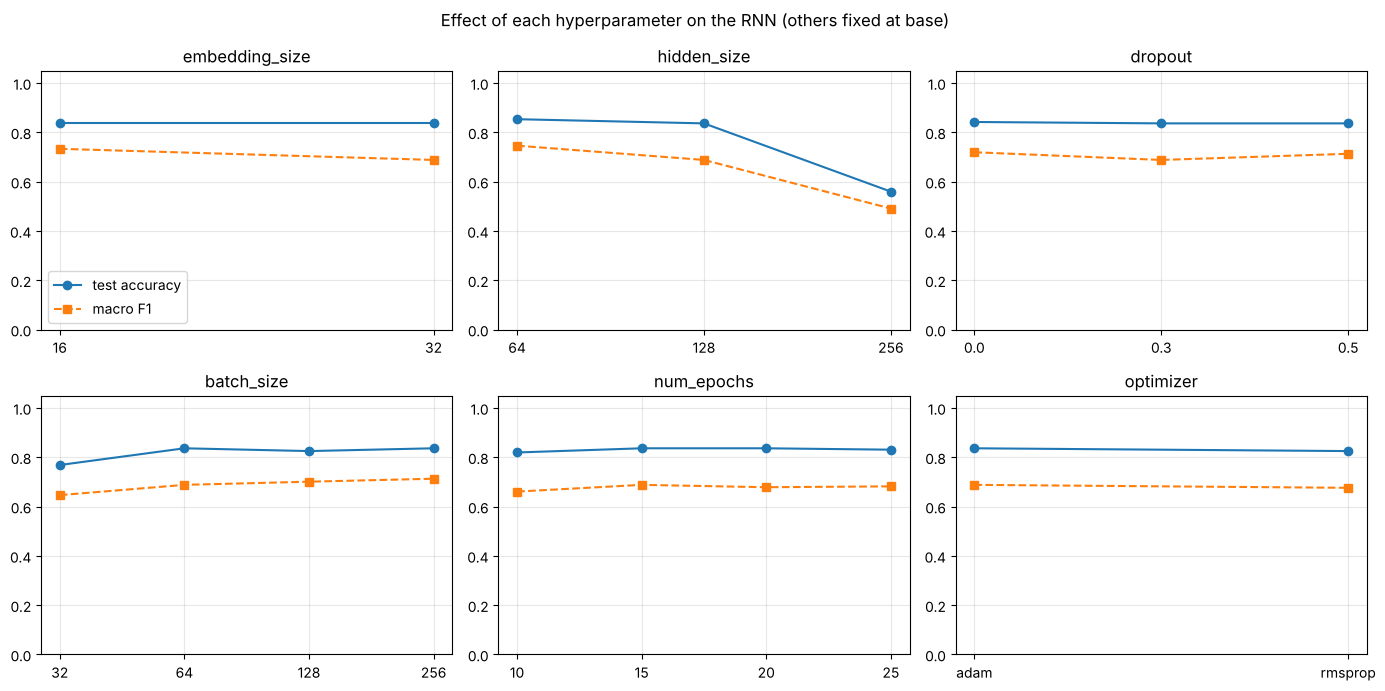

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, (param, values) in zip(axes.ravel(), GRID.items()):
    s = sweep[sweep["varied"] == param]
    x = [str(v) for v in s[param]]
    ax.plot(x, s["test_acc"], "o-", label="test accuracy")
    ax.plot(x, s["macro_f1"], "s--", label="macro F1")
    ax.set_title(param); ax.set_ylim(0, 1.05); ax.grid(alpha=.3)
axes[0, 0].legend()
plt.suptitle("Effect of each hyperparameter on the RNN (others fixed at base)"); plt.tight_layout(); plt.show()

In [9]:
best = sweep.sort_values(["macro_f1", "test_acc"], ascending=False).iloc[0]
print("Best single-change config by macro F1:")
print(best[["embedding_size", "hidden_size", "dropout", "batch_size", "num_epochs", "optimizer",
            "test_acc", "macro_f1"]])

# combine the best value of every hyperparameter into one final RNN config
BEST_CFG = {}
for param in GRID:
    s = sweep[sweep["varied"] == param].sort_values(["macro_f1", "test_acc"], ascending=False)
    v = s.iloc[0][param]
    BEST_CFG[param] = v.item() if hasattr(v, "item") else v
print("\nCombined best-per-parameter config:", BEST_CFG)

Best single-change config by macro F1:
embedding_size          32
hidden_size             64
dropout                0.3
batch_size              64
num_epochs              15
optimizer             adam
test_acc          0.853107
macro_f1          0.745802
Name: 2, dtype: object

Combined best-per-parameter config: {'embedding_size': 16, 'hidden_size': 64, 'dropout': 0.0, 'batch_size': 256, 'num_epochs': 15, 'optimizer': 'adam'}


## 5. Final RNN vs baseline ANN (same config, same data split)

Single best sweep config beat the combined one, using it: {'embedding_size': 32, 'hidden_size': 64, 'dropout': 0.3, 'batch_size': 64, 'num_epochs': 15, 'optimizer': 'adam'}


Final config: {'embedding_size': 32, 'hidden_size': 64, 'dropout': 0.3, 'batch_size': 64, 'num_epochs': 15, 'optimizer': 'adam'}


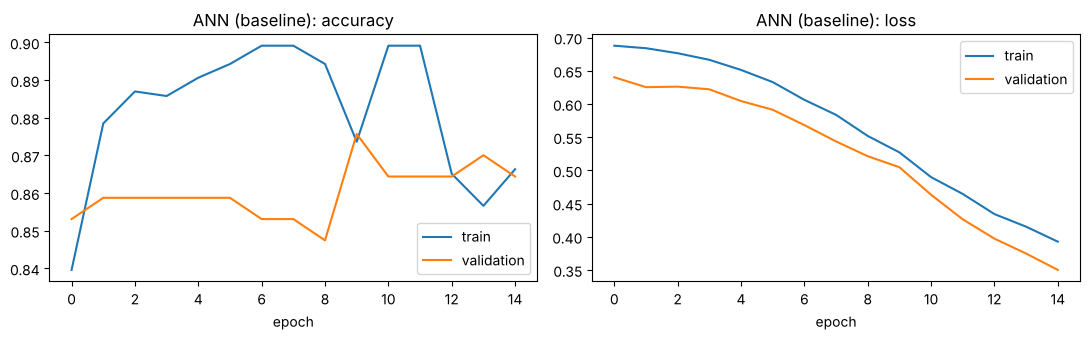

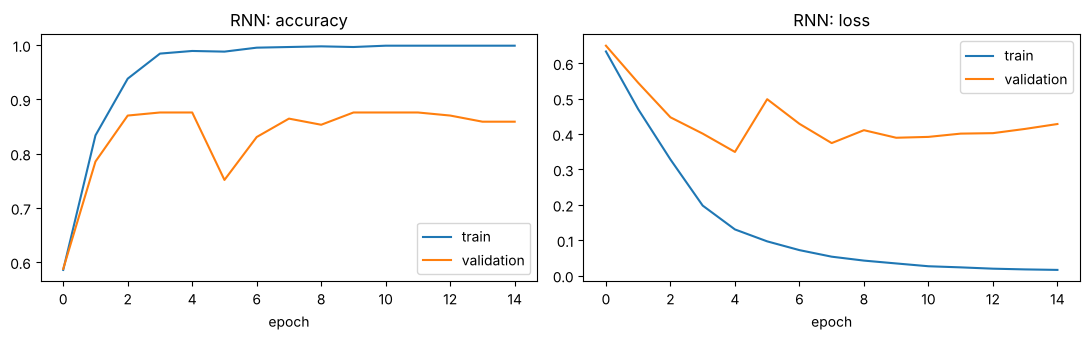

In [10]:
results, histories, preds = [], {}, {}
for kind in ["ann", "rnn"]:
    r, h, m, p = run(kind, **BEST_CFG)
    results.append(r); histories[kind] = h; preds[kind] = p

# keep whichever RNN is better: combined config or the single best sweep run
if best["macro_f1"] > results[1]["macro_f1"]:
    cfg2 = {k: (best[k].item() if hasattr(best[k], "item") else best[k]) for k in GRID}
    print("Single best sweep config beat the combined one, using it:", cfg2)
    BEST_CFG = cfg2
    results = []
    for kind in ["ann", "rnn"]:
        r, h, m, p = run(kind, **BEST_CFG)
        results.append(r); histories[kind] = h; preds[kind] = p
print("Final config:", BEST_CFG)

plot_history(histories["ann"], "ANN (baseline)")
plot_history(histories["rnn"], "RNN")

## 6. Bonus: LSTM

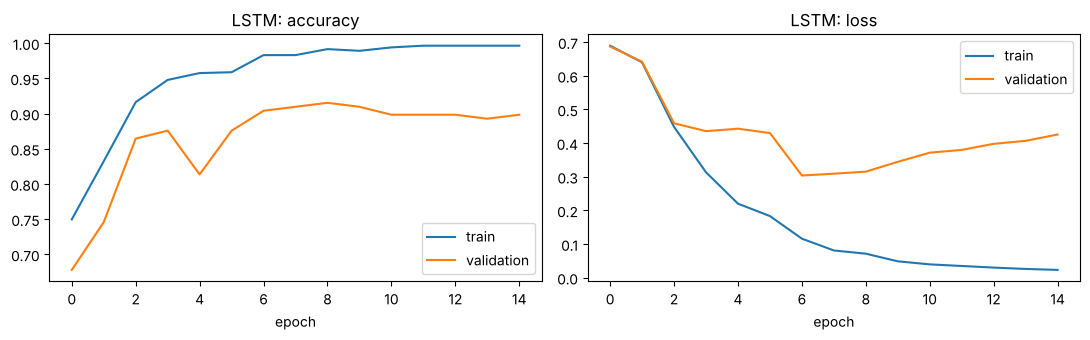

In [11]:
r, h, m, p = run("lstm", **BEST_CFG)
results.append(r); histories["lstm"] = h; preds["lstm"] = p
plot_history(h, "LSTM")

## 7. Comparison: ANN vs RNN vs LSTM

,model,train_acc,val_acc,test_acc,test_loss,macro_f1,train_time_s
0,ANN,0.866,0.864,0.870,0.371,0.718,5.568
1,RNN,0.999,0.859,0.853,0.394,0.746,17.684
2,LSTM,0.996,0.898,0.864,0.462,0.729,30.416


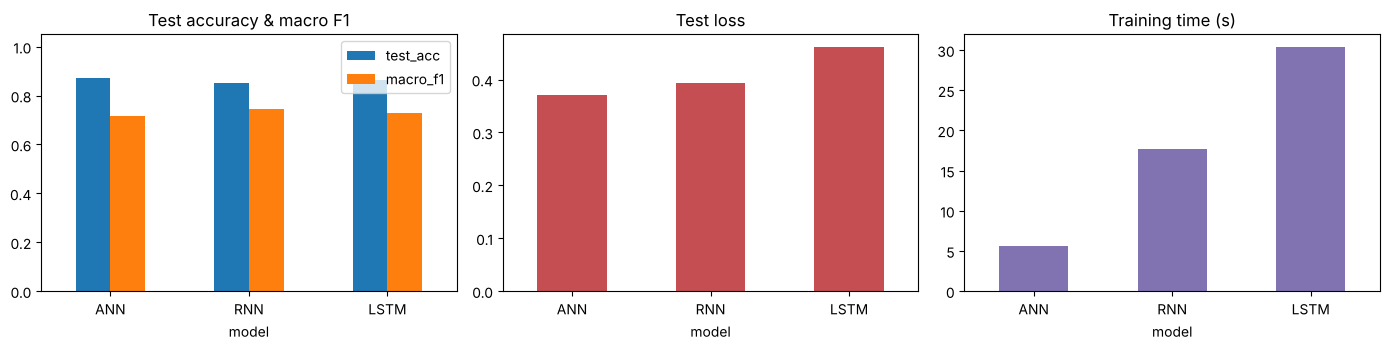

In [12]:
comp = pd.DataFrame(results)[["model", "train_acc", "val_acc", "test_acc", "test_loss", "macro_f1", "train_time_s"]]
display(comp.round(3))

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
comp.plot.bar(x="model", y=["test_acc", "macro_f1"], ax=ax[0], rot=0, ylim=(0, 1.05), title="Test accuracy & macro F1")
comp.plot.bar(x="model", y="test_loss", ax=ax[1], rot=0, legend=False, color="#C44E52", title="Test loss")
comp.plot.bar(x="model", y="train_time_s", ax=ax[2], rot=0, legend=False, color="#8172B2", title="Training time (s)")
plt.tight_layout(); plt.show()

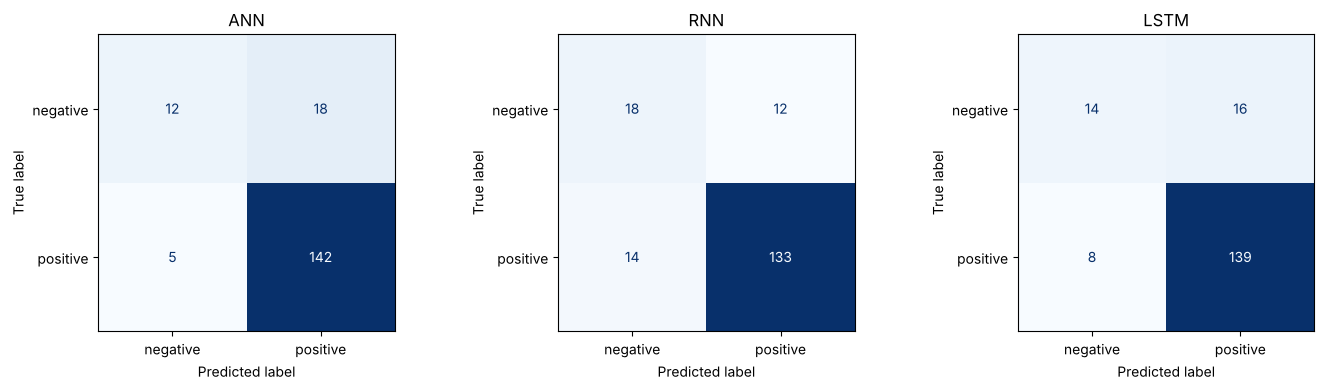

===== ANN =====
              precision    recall  f1-score   support

    negative      0.706     0.400     0.511        30
    positive      0.887     0.966     0.925       147

    accuracy                          0.870       177
   macro avg      0.797     0.683     0.718       177
weighted avg      0.857     0.870     0.855       177

===== RNN =====
              precision    recall  f1-score   support

    negative      0.562     0.600     0.581        30
    positive      0.917     0.905     0.911       147

    accuracy                          0.853       177
   macro avg      0.740     0.752     0.746       177
weighted avg      0.857     0.853     0.855       177

===== LSTM =====
              precision    recall  f1-score   support

    negative      0.636     0.467     0.538        30
    positive      0.897     0.946     0.921       147

    accuracy                          0.864       177
   macro avg      0.767     0.706     0.729       177
weighted avg      0.853  

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, k in zip(ax, ["ann", "rnn", "lstm"]):
    ConfusionMatrixDisplay(confusion_matrix(y_test, preds[k]), display_labels=["negative", "positive"]).plot(
        ax=a, cmap="Blues", colorbar=False)
    a.set_title(k.upper())
plt.tight_layout(); plt.show()

for k in ["ann", "rnn", "lstm"]:
    print(f"===== {k.upper()} =====")
    print(classification_report(y_test, preds[k], target_names=["negative", "positive"], digits=3))

In [14]:
# quick sanity check on unseen sentences
_, _, best_model, _ = run("lstm", **BEST_CFG)
samples = ["This tablet is amazing, battery lasts all day and the screen is great",
           "Stopped working after two weeks, waste of money, do not buy",
           "It is not good at all, very slow and the charger broke"]
probs = best_model.predict(vectorizer(np.array([clean_text(s) for s in samples])), verbose=0).ravel()
for s, pr in zip(samples, probs):
    print(f"{'POSITIVE' if pr >= .5 else 'NEGATIVE'} ({pr:.2f})  {s}")

POSITIVE (0.98)  This tablet is amazing, battery lasts all day and the screen is great
NEGATIVE (0.05)  Stopped working after two weeks, waste of money, do not buy
NEGATIVE (0.36)  It is not good at all, very slow and the charger broke


## 8. Observations and conclusion

In [15]:
# numbers for the write-up below, printed so the conclusion matches this run
for _, r in comp.iterrows():
    print(f"{r['model']:>4}: test acc {r['test_acc']:.3f}, macro F1 {r['macro_f1']:.3f}, loss {r['test_loss']:.3f}, time {r['train_time_s']:.1f}s")

 ANN: test acc 0.870, macro F1 0.718, loss 0.371, time 5.6s
 RNN: test acc 0.853, macro F1 0.746, loss 0.394, time 17.7s
LSTM: test acc 0.864, macro F1 0.729, loss 0.462, time 30.4s


### What the hyperparameter sweep showed (RNN)

- **Hidden size** had the biggest effect. 64 units gave the best RNN (test acc 0.853, macro F1 0.746). 256 units collapsed to 0.559 accuracy: a big SimpleRNN on only 823 training reviews is hard to train, and the gradients through 150 time steps either blow up or die out.
- **Embedding size** 16 and 32 gave the same accuracy (0.836), but 16 had a better macro F1 (0.733 vs 0.688). With a vocabulary built from ~800 reviews, a smaller vector is enough.
- **Dropout** made little difference here (0.836 to 0.842). Training accuracy hits ~99% within 15 epochs for every setting, so the model overfits whatever dropout is used.
- **Batch size 32** was the worst (0.768). Small batches give noisy updates and the RNN overfit faster. 64 to 256 were all around 0.83.
- **Epochs**: 15 was the sweet spot. After that training accuracy stays at ~100% while test loss goes up (0.43 at 15 epochs, 0.525 at 25), which is overfitting.
- **Optimizer**: adam and rmsprop came out close. rmsprop gave a lower loss, adam a slightly better F1. Running it twice gave slightly different rmsprop numbers, so the gap is within run-to-run noise.

### ANN vs RNN vs LSTM

| Model | Test acc | Macro F1 | Negative recall | Train time |
|---|---|---|---|---|
| ANN (baseline) | 0.870 | 0.718 | 0.40 | ~6 s |
| RNN | 0.853 | 0.746 | 0.60 | ~18 s |
| LSTM (bonus) | 0.864 | 0.729 | 0.47 | ~30 s |

- The ANN has the highest plain accuracy, but most of that comes from predicting "positive" (it only finds 12 of the 30 negative reviews). Since 83% of the test set is positive, accuracy flatters it.
- The RNN finds 18 of the 30 negative reviews and has the best macro F1. Reading words in order lets it pick up phrases like "not good" and "stopped working", which an averaged bag of words loses.
- The LSTM gets the best validation accuracy (0.898) and sits between the two on the test set. Its gates (forget, input, output) and the separate cell state let the gradient flow back through long reviews without vanishing, which is why it trained stably where the 256-unit SimpleRNN did not. It is also the slowest, about 5x the ANN.

### Limitations

The dataset is small (1,177 labelled reviews, only 200 negative), so a few reviews change the test score by several points and the differences between models are not large. With more data, or pretrained embeddings like GloVe, the sequence models should pull further ahead of the ANN. A bidirectional LSTM and early stopping on validation loss would be the next things to try.
